# Regression with LightGBM V3.0 (oracle) — Income, Gradient-Boosted Trees

**Version:** V3.0 (GBDT ceiling check, not a taught-list submission). **Role:** reference oracle for the V3.0 scratch twin.
Same cleaned data / same 80-20 split / seed 42 as `regression_pytorch_V1_1.ipynb` (copied verbatim). LightGBM trains directly on raw-$ `Income` — no log1p/z-scoring needed, since V1.0-V2.0 already report metrics in raw $ after inverse-transform. Weights → `./weights_V3_0/`.


In [1]:
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
np.random.seed(SEED)
os.makedirs("weights_V3_0", exist_ok=True)
print("lightgbm:", lgb.__version__)

# ---- 1. LOAD DATA (identical to V1.1) ----
df = pd.read_csv("marketing_campaign.csv", sep="\t")
df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
ref_date = df["Dt_Customer"].max()
df["Customer_Tenure_Days"] = (ref_date - df["Dt_Customer"]).dt.days
df["Age"] = 2014 - df["Year_Birth"]
df = df[~df["Year_Birth"].isin([1893, 1899, 1900])].copy()
df = df[df["Income"] != 666666].copy()  # drop $666,666 income outlier (same treatment as Year_Birth sentinels)
df["Marital_Status"] = df["Marital_Status"].replace({"Absurd": "Single", "YOLO": "Single", "Alone": "Single"})
df = df.dropna(subset=["Income"]).copy()
print("cleaned:", df.shape, "| Income median:", round(df["Income"].median()))

REG_FEATURES = [
    "NumCatalogPurchases", "MntMeatProducts", "MntWines", "NumWebVisitsMonth",
    "MntSweetProducts", "MntFruits", "NumWebPurchases", "MntGoldProds",
    "NumStorePurchases", "MntFishProducts", "Kidhome", "Age", "NumDealsPurchases",
]
X_full = df[REG_FEATURES].values
y_full = df["Income"].astype(float).values
print(f"features: {len(REG_FEATURES)} dims (all numeric)")

lightgbm: 4.7.0
cleaned: (2212, 28) | Income median: 51371
features: 13 dims (all numeric)


In [2]:
X_temp, X_test, y_temp, y_test = train_test_split(X_full, y_full, test_size=0.20, random_state=SEED)
print(f"train {X_temp.shape} test {X_test.shape} | y mean {y_full.mean():.0f} std {y_full.std():.0f}")

train (1769, 13) test (443, 13) | y mean 51959 std 21522


## Train

`LGBMRegressor` (MSE objective) trained directly on raw-$ `Income`. A 10% slice carved out of the train split (not the test split) drives early stopping — the test split stays exactly the one V1.1 uses.

In [3]:
X_tr, X_val, y_tr, y_val = train_test_split(X_temp, y_temp, test_size=0.10, random_state=SEED)

reg = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=SEED,
    verbosity=-1,
)
reg.fit(
    X_tr, y_tr,
    eval_set=[(X_tr, y_tr), (X_val, y_val)],
    eval_names=["train", "valid"],
    eval_metric="rmse",
    callbacks=[lgb.early_stopping(50, verbose=False)],
)
print(f"best_iteration: {reg.best_iteration_}")

history = pd.DataFrame({
    "round": range(1, len(reg.evals_result_["train"]["rmse"]) + 1),
    "train_metric": reg.evals_result_["train"]["rmse"],
    "val_metric": reg.evals_result_["valid"]["rmse"],
})
history.to_csv("weights_V3_0/regression_lightgbm_history.csv", index=False)
print(f"history: {len(history)} rounds -> weights_V3_0/regression_lightgbm_history.csv")


best_iteration: 98
history: 148 rounds -> weights_V3_0/regression_lightgbm_history.csv


/home/waroon/SecondYear/FirstSemester/IntroMLHomework/Data/.venv/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


## Evaluate on the V1.1 test set (raw $)

In [4]:
pred = reg.predict(X_test)

test_mse = float(mean_squared_error(y_test, pred))
metrics = {
    "test_loss_MSE_raw": round(test_mse, 1),
    "rmse": round(float(np.sqrt(test_mse)), 1),
    "mae": round(float(mean_absolute_error(y_test, pred)), 1),
    "r2": round(float(r2_score(y_test, pred)), 4),
    "n_test": int(len(y_test)), "seed": SEED, "best_iteration": int(reg.best_iteration_),
}
print(json.dumps(metrics, indent=2))
with open("weights_V3_0/regression_lightgbm_test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
for i in range(5):
    print(f"  pred={pred[i]:.0f} true={y_test[i]:.0f}")

{
  "test_loss_MSE_raw": 84947282.4,
  "rmse": 9216.7,
  "mae": 5758.4,
  "r2": 0.8212,
  "n_test": 443,
  "seed": 42,
  "best_iteration": 98
}
  pred=66231 true=62450
  pred=36290 true=37235
  pred=67584 true=65492
  pred=41688 true=42618
  pred=28719 true=26997


## Save booster + feature importance

saved to weights_V3_0/


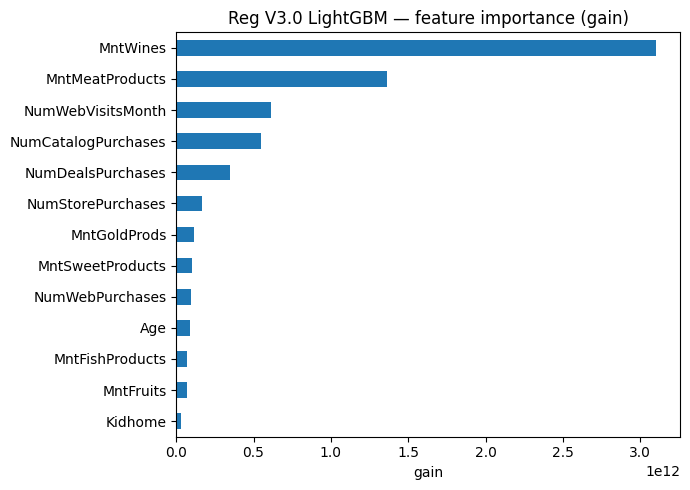

MntWines               3.102190e+12
MntMeatProducts        1.359923e+12
NumWebVisitsMonth      6.138315e+11
NumCatalogPurchases    5.494869e+11
NumDealsPurchases      3.448253e+11
dtype: float64


In [5]:
reg.booster_.save_model("weights_V3_0/regression_lightgbm.txt")
print("saved to weights_V3_0/")

imp = pd.Series(reg.booster_.feature_importance(importance_type="gain"), index=REG_FEATURES).sort_values()
plt.figure(figsize=(7, 5))
imp.plot(kind="barh")
plt.xlabel("gain"); plt.title("Reg V3.0 LightGBM — feature importance (gain)")
plt.tight_layout()
plt.savefig("media/featimp_reg_V3_0.png", dpi=150)
plt.show()
print(imp.sort_values(ascending=False).head(5))